In [ ]:
# Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display all columns when printing DataFrames.
pd.set_option("display.max_columns", None)

# Set a readable default chart size.
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Loading the dataset
PROJECT_ROOT = Path.cwd()


if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "Bengaluru_House_Data.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (13320, 9)


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [3]:
# Find the missing values
missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": (
        missing_values / len(df) * 100
    ).round(2)
})

display(missing_report.sort_values(
    by="Missing Percentage",
    ascending=False
))

,Missing Count,Missing Percentage
society,5502,41.31
balcony,609,4.57
bath,73,0.55
size,16,0.12
location,1,0.01
area_type,0,0.00
availability,0,0.00
total_sqft,0,0.00
price,0,0.00


In [7]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

CLEANED_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "cleaned_houses.csv"
)

df = pd.read_csv(CLEANED_PATH)

print("Cleaned dataset shape:", df.shape)

display(df.head())

Cleaned dataset shape: (12671, 11)


,area_type,availability,location,size,society,total_sqft,bath,balcony,price,bhk,price_per_sqft
0,Super built-up Area,19-Dec,electronic city phase ii,2 BHK,Coomee,1056.0,2.0,1.0,39.07,2,3699.810606
1,Plot Area,Ready To Move,chikka tirupathi,4 Bedroom,Theanmp,2600.0,5.0,3.0,120.00,4,4615.384615
2,Built-up Area,Ready To Move,uttarahalli,3 BHK,NaN,1440.0,2.0,3.0,62.00,3,4305.555556
3,Super built-up Area,Ready To Move,lingadheeranahalli,3 BHK,Soiewre,1521.0,3.0,1.0,95.00,3,6245.890861
4,Super built-up Area,Ready To Move,kothanur,2 BHK,NaN,1200.0,2.0,1.0,51.00,2,4250.000000


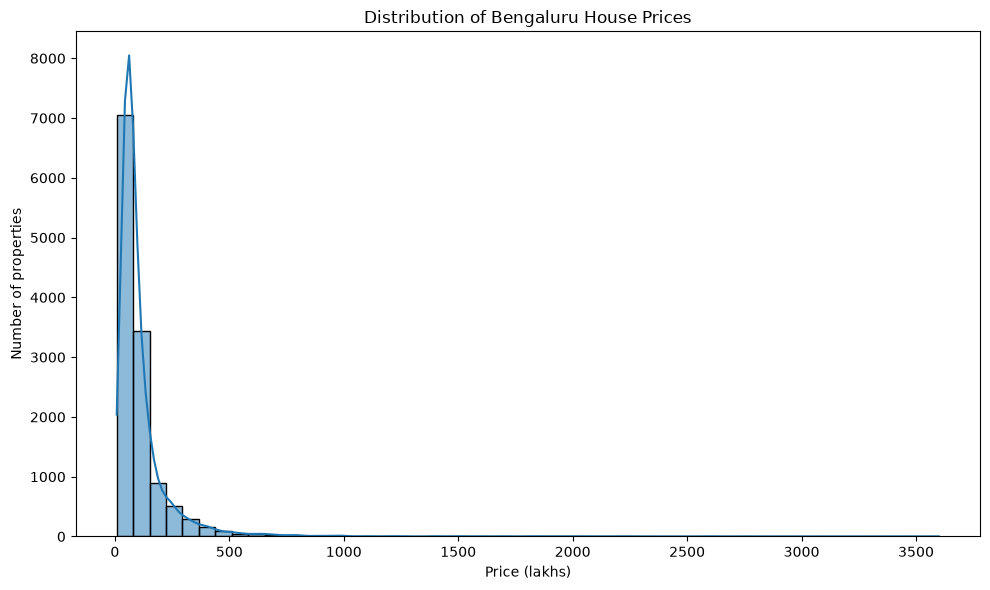

In [8]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="price",
    bins=50,
    kde=True
)

plt.title("Distribution of Bengaluru House Prices")
plt.xlabel("Price (lakhs)")
plt.ylabel("Number of properties")
plt.tight_layout()
plt.show()

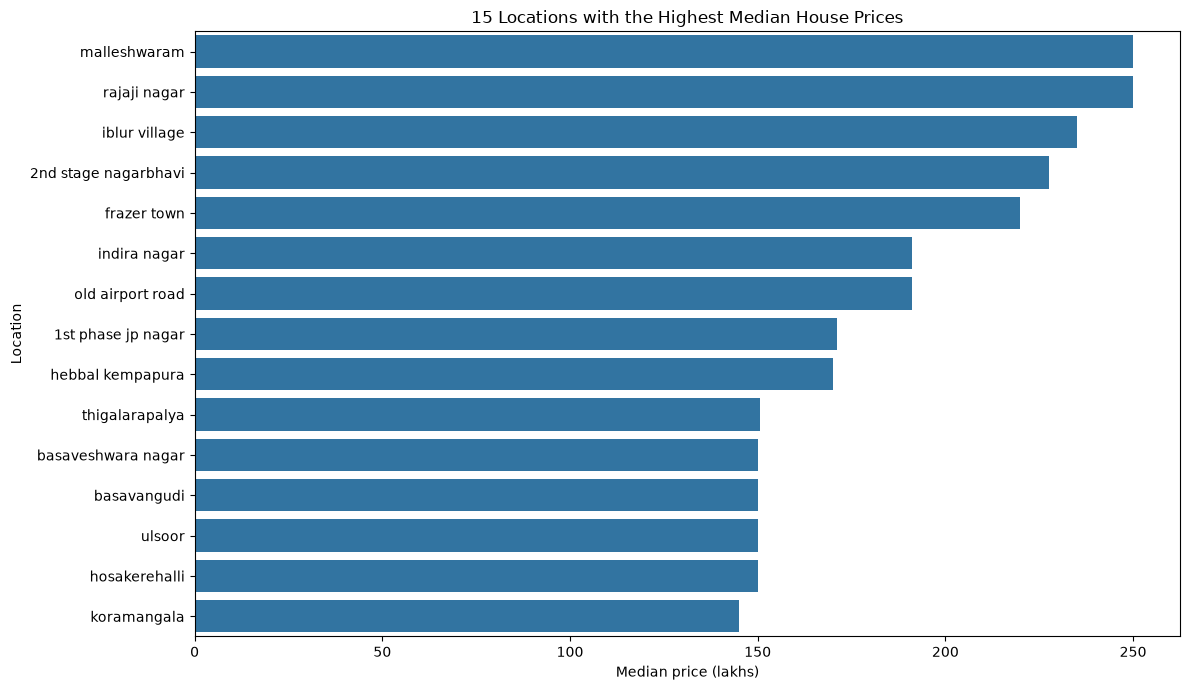

In [9]:
location_counts = df["location"].value_counts()

common_locations = location_counts[
    location_counts >= 20
].index

location_prices = df[
    df["location"].isin(common_locations)
]

top_locations = (
    location_prices.groupby("location")["price"]
    .median()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_locations.values,
    y=top_locations.index
)

plt.title("15 Locations with the Highest Median House Prices")
plt.xlabel("Median price (lakhs)")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

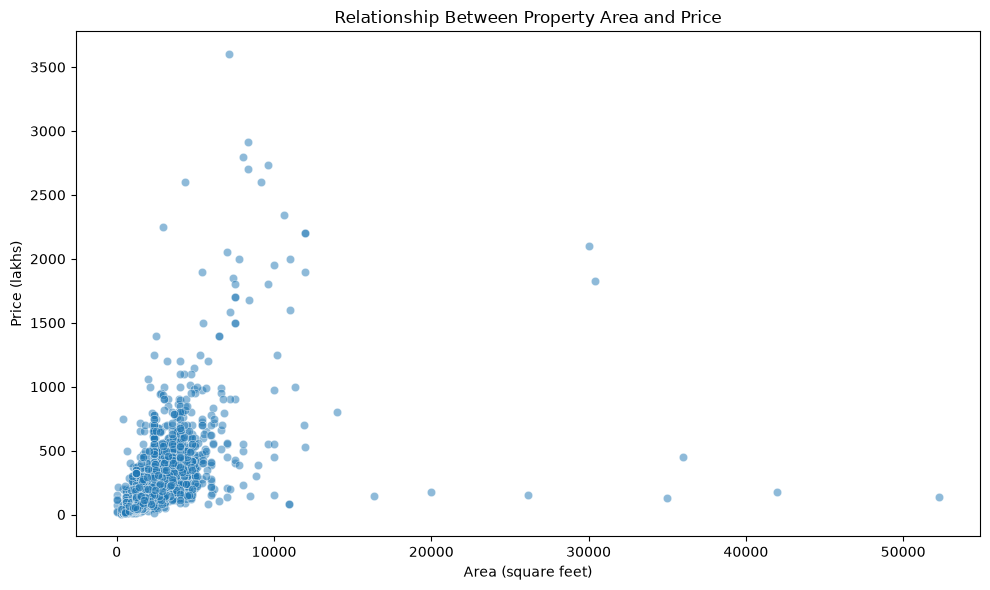

In [10]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="total_sqft",
    y="price",
    alpha=0.5
)

plt.title("Relationship Between Property Area and Price")
plt.xlabel("Area (square feet)")
plt.ylabel("Price (lakhs)")
plt.tight_layout()
plt.show()

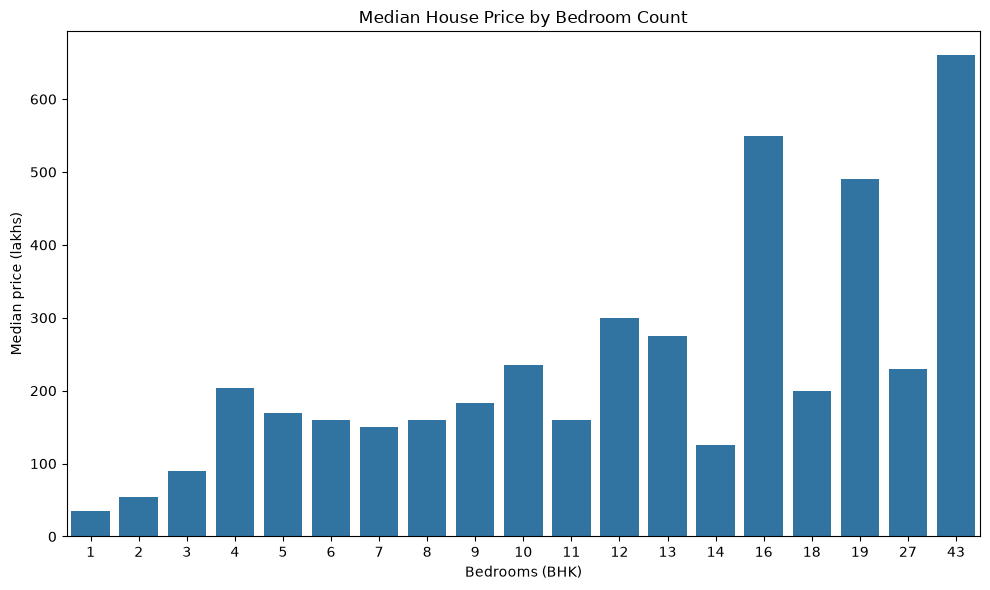

In [11]:
bedroom_prices = (
    df.groupby("bhk")["price"]
    .median()
    .sort_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=bedroom_prices.index.astype(str),
    y=bedroom_prices.values
)

plt.title("Median House Price by Bedroom Count")
plt.xlabel("Bedrooms (BHK)")
plt.ylabel("Median price (lakhs)")
plt.tight_layout()
plt.show()

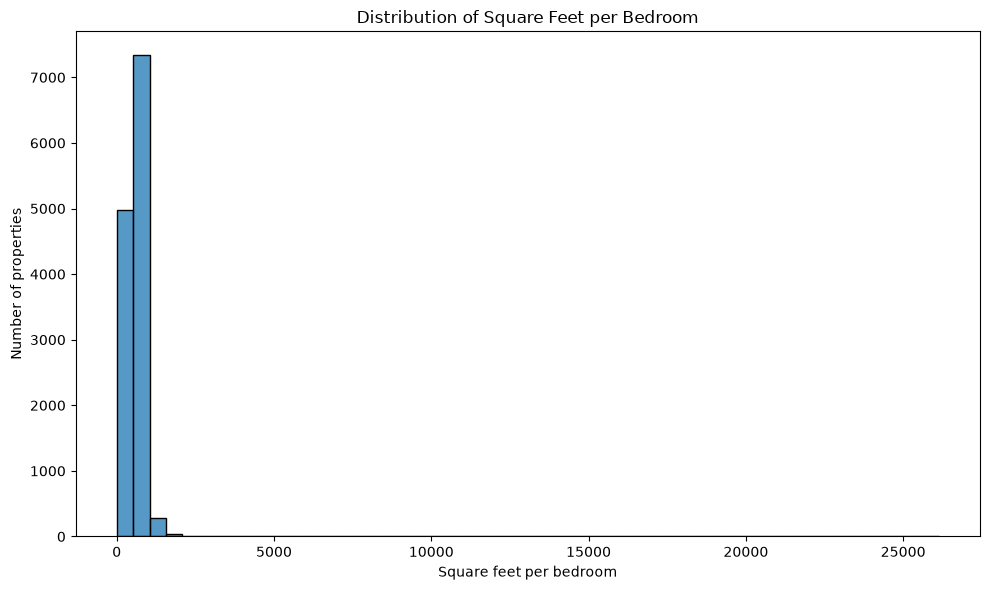

In [12]:
df["sqft_per_bhk"] = (
    df["total_sqft"] / df["bhk"]
)

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="sqft_per_bhk",
    bins=50
)

plt.title("Distribution of Square Feet per Bedroom")
plt.xlabel("Square feet per bedroom")
plt.ylabel("Number of properties")
plt.tight_layout()
plt.show()

In [13]:
display(
    df.sort_values(
        by="bath",
        ascending=False
    )[
        [
            "location",
            "size",
            "total_sqft",
            "bath",
            "balcony",
            "price"
        ]
    ].head(20)
)

,location,size,total_sqft,bath,balcony,price
4572,munnekollal,43 Bedroom,2400.0,40.0,0.0,660.0
1689,2electronic city phase ii,27 BHK,8000.0,27.0,0.0,230.0
11043,1kasavanhalli,18 Bedroom,1200.0,18.0,NaN,200.0
3301,1hanuman nagar,19 BHK,2000.0,16.0,NaN,490.0
3529,koramangala industrial layout,16 BHK,10000.0,16.0,NaN,550.0
4794,1channasandra,14 BHK,1250.0,15.0,0.0,125.0
1062,btm 1st stage,9 Bedroom,3300.0,14.0,NaN,500.0
9523,1hoysalanagar,13 BHK,5425.0,13.0,0.0,275.0
12440,defence colony,10 Bedroom,7150.0,13.0,NaN,3600.0
10240,electronic city,9 Bedroom,1200.0,13.0,NaN,150.0


In [14]:
display(
    df.sort_values(
        by="price",
        ascending=False
    )[
        [
            "location",
            "size",
            "total_sqft",
            "bath",
            "balcony",
            "price"
        ]
    ].head(20)
)

,location,size,total_sqft,bath,balcony,price
12440,defence colony,10 Bedroom,7150.0,13.0,NaN,3600.0
10597,ashok nagar,4 BHK,8321.0,5.0,2.0,2912.0
12560,defence colony,6 Bedroom,8000.0,6.0,3.0,2800.0
11232,sadashiva nagar,5 Bedroom,9600.0,7.0,2.0,2736.0
3109,shanthala nagar,5 BHK,8321.0,5.0,3.0,2700.0
11864,dollars colony,4 Bedroom,4350.0,8.0,NaN,2600.0
12557,ramakrishnappa layout,4 Bedroom,9200.0,4.0,NaN,2600.0
9875,5th block jayanagar,4 Bedroom,10624.0,4.0,2.0,2340.0
6220,bommenahalli,4 Bedroom,2940.0,3.0,2.0,2250.0
598,malleshwaram,7 BHK,12000.0,7.0,3.0,2200.0
